In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
import ast
import scipy
import mdtraj as md
from typing import Dict, Tuple
import os

# matplotlib settings
# --- Publication style settings ---
plt.rcParams.update({
    # Font
    "font.family": "Times New Roman",
    "font.serif": ["Arial"],  # or other preferred serif font
    "mathtext.fontset": "cm",            # Computer Modern for math text
    "text.usetex": False,                 # Use LaTeX for text rendering]
    "pdf.fonttype": 42,                 # Use LaTeX for text rendering

    # Figure
    "figure.figsize": (6, 4),            # width, height in inches
    "figure.dpi": 150,                   # medium resolution

    # Axes
    "axes.titlesize": 12,
    "axes.labelsize": 10,
    "axes.linewidth": 1.2,
    "axes.grid": True,                   # optional, remove if you want no grid
    "grid.linestyle": "--",
    "grid.alpha": 0.7,

    # Ticks
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "xtick.direction": "in",
    "ytick.direction": "in",
    "xtick.top": True,
    "ytick.right": True,

    # Lines
    "lines.linewidth": 2,
    "lines.markersize": 6,

    # Legend
    "legend.fontsize": 10,
    "legend.frameon": False
})

def find_xtc_filenames(path_to_dir, suffix=".xtc"):
    filenames = os.listdir(path_to_dir)
    return [filename for filename in filenames if filename.endswith(suffix)]

# --- Utility functions ---
def RMSE(actual, predicted):
    actual = np.array(actual)
    predicted = np.array(predicted)
    return np.sqrt(np.mean((actual - predicted)**2))

def load_pf_data(protein, model_name, ensemble_dir="MD_DATA", exp_dir="EXP_DATA/PF_Nguyen_2018"):
    exp = pd.read_csv(f"../../{exp_dir}/{protein}.csv")
    residues = np.loadtxt(f"../../{ensemble_dir}/{protein}/{model_name}/exp_residues.txt")
    priorPF = np.exp(np.loadtxt(f"../../{ensemble_dir}/{protein}/{model_name}/prior_lnPF.txt"))
    if model_name in ('rewBV2006', 'rewBV2006ang'):
        rewPF = np.exp(np.loadtxt(f"../../{ensemble_dir}/{protein}/{model_name}/rew_lnPF.txt"))
        stats = pd.read_csv(f"../../{ensemble_dir}/{protein}/{model_name}/stats_df.csv")
        rewdata = np.loadtxt(f"../../{ensemble_dir}/{protein}/{model_name}/reweighting_chi2_phi_theta.txt")
    else:
        rewPF = np.exp(np.loadtxt(f"../../{ensemble_dir}/{protein}/{model_name}/log_lambda_rew_lnPF.txt"))
        stats = pd.read_csv(f"../../{ensemble_dir}/{protein}/{model_name}/log_lambda_stats_df.csv")
        rewdata = np.loadtxt(f"../../{ensemble_dir}/{protein}/{model_name}/log_lambda_reweighting_chi2_phi_theta.txt")
    chi2, phi, thetas = rewdata[0, :], rewdata[1, :], rewdata[2, :]
    idxs = [list(exp["Model_residue"]).index(ele) for ele in residues]
    return exp, residues, priorPF, rewPF, chi2, phi, thetas, stats, idxs

def find_elbow(x, y):
    # Convert to numpy arrays
    x = np.array(x)
    y = np.array(y)

    # Sort x (and y) if needed, but keep track of original indices
    if not np.all(np.diff(x) >= 0):
        idx_sort = np.argsort(x)
        x_sorted = x[idx_sort]
        y_sorted = y[idx_sort]
    else:
        idx_sort = np.arange(len(x))
        x_sorted, y_sorted = x, y

    # Line between first and last point
    p1 = np.array([x_sorted[0], y_sorted[0]])
    p2 = np.array([x_sorted[-1], y_sorted[-1]])
    line_vec = p2 - p1
    line_vec_norm = line_vec / np.linalg.norm(line_vec)

    # Distances from each point to the line
    vec_from_p1 = np.vstack([x_sorted - p1[0], y_sorted - p1[1]]).T
    proj_len = np.dot(vec_from_p1, line_vec_norm)
    proj_point = np.outer(proj_len, line_vec_norm) + p1
    dist = np.linalg.norm(vec_from_p1 - (proj_point - p1), axis=1)

    # Elbow = point with maximum distance
    idx_elbow_sorted = np.argmax(dist)
    idx_elbow_original = idx_sort[idx_elbow_sorted]

    return idx_elbow_original, x[idx_elbow_original], y[idx_elbow_original]

# Function to calculate helical fraction
def helical_fraction(ss_line):
    helix_chars = {'H', 'G', 'I'}
    n_residues = len(ss_line)
    n_helical = sum(1 for c in ss_line if c in helix_chars)
    return n_helical / n_residues

# Function to calculate per-residue helicity per frame
def dssp_to_helicity(dssp_lines):
    """
    Convert DSSP strings into a binary helicity matrix.
    
    Parameters
    ----------
    dssp_lines : list of str
        Each entry corresponds to one frame.
        Each string is the DSSP assignment per residue for that frame.
    
    Returns
    -------
    helicity : np.ndarray
        Array of shape (n_frames, n_residues).
        1 = helix ('H', 'G', 'I'), 0 = non-helix.
    """
    helix_codes = {'H', 'G', 'I'}
    
    n_frames = len(dssp_lines)
    n_residues = len(dssp_lines[0])
    
    helicity = np.zeros((n_frames, n_residues), dtype=int)
    
    for i, line in enumerate(dssp_lines):
        helicity[i, :] = [1 if c in helix_codes else 0 for c in line]
    
    return helicity

# functions for analysis of chemical shifts
# functions for chemical shift analysis
# Constants
# from here : https://link.springer.com/article/10.1007/s10858-010-9433-9 (average prediction error of the forward model)
CS_UNCERTAINTIES = {
    "Sparta+": {"C": 1.09, "CA": 0.94, "CB": 1.14, "N": 2.45, "H": 0.49, "HA": 0.25}
}

AA_dict = {
    "A": "ALA",  # Alanine
    "R": "ARG",  # Arginine
    "N": "ASN",  # Asparagine
    "D": "ASP",  # Aspartic Acid
    "C": "CYS",  # Cysteine
    "E": "GLU",  # Glutamic Acid
    "Q": "GLN",  # Glutamine
    "G": "GLY",  # Glycine
    "H": "HIS",  # Histidine
    "I": "ILE",  # Isoleucine
    "L": "LEU",  # Leucine
    "K": "LYS",  # Lysine
    "M": "MET",  # Methionine
    "F": "PHE",  # Phenylalanine
    "P": "PRO",  # Proline
    "S": "SER",  # Serine
    "T": "THR",  # Threonine
    "W": "TRP",  # Tryptophan
    "Y": "TYR",  # Tyrosine
    "V": "VAL",  # Valine
}

# atom types to use during reweighting: choose from [ HA CA HN N C CB ]
ATOM_TYPES = ["CA", "HA", "CB", "HN", "N", "C", "H"] # HN and H present because "H" is used in potenci shift tables
ATOM_TYPES = ["CA"] 

def load_experimental_shifts(path: str, ATOM_TYPES) -> Dict[Tuple[int, str], float]:
    """Load experimental chemical shifts. Returns first column is 'resSeq', second is 'name', third is 'value'."""
    df = pd.read_csv(path, delim_whitespace=True)
    residues = []
    names = []
    values = []
    for i in range(len(df)):
        res = int(df['#RESID'][i])
        for col in df.columns[2:]:
            if col in ATOM_TYPES: # only including specified nuclei
                if col=='HN':
                    try:
                        value = float(df[col][i])
                        if value>0:
                            residues.append(res)
                            names.append('H') # rename HN to H
                            values.append(value)
                    except:
                        continue
                else:
                    try:
                        value = float(df[col][i])
                        if value>0:
                            residues.append(res)
                            names.append(col)
                            values.append(value)
                    except:
                        continue
            else:
                continue
    return {(int(res), str(name)): float(value) for res, name, value in zip(residues, names, values)}

def load_and_filter_experimental_shifts(path: str, bmrb_stats_path: str, sigma_cutoff = 3.0, ATOM_TYPES = ATOM_TYPES) -> Dict[Tuple[int, str], float]:
    """Load experimental chemical shifts. Returns first column is 'resSeq', second is 'name', third is 'value'."""
    df = pd.read_csv(path, delim_whitespace=True)
    bmrb = pd.read_csv(bmrb_stats_path)
    residues = []
    names = []
    values = []
    for i in range(len(df)):
        res = int(df['#RESID'][i])
        resname = str(df['RESNAME'][i])
        if len(resname)==1:
            resname = AA_dict[resname] # convert to 3-letter code if 1-letter
        for col in df.columns[2:]:
            if col in ATOM_TYPES: # only including specified nuclei
                try:
                    value = float(df[col][i])
                    if value>0:
                        # extract bmrb avg and sd
                        if col=='HN':
                            row = bmrb[(bmrb["comp_id"] == resname) & (bmrb["atom_id"] == 'H')]
                            bmrb_mu = row["avg"].values[0]
                            bmrb_sd = row["std"].values[0]
                            if np.abs(value - bmrb_mu) < bmrb_sd * sigma_cutoff:
                                residues.append(res)
                                names.append('H') # rename HN to H
                                values.append(value)
                        else:
                            row = bmrb[(bmrb["comp_id"] == resname) & (bmrb["atom_id"] == col)]
                            bmrb_mu = row["avg"].values[0]
                            bmrb_sd = row["std"].values[0]
                            if np.abs(value - bmrb_mu) < bmrb_sd * sigma_cutoff:
                                residues.append(res)
                                names.append(col)
                                values.append(value)
                except:
                    continue
            else:
                continue
    return {(int(res), str(name)): float(value) for res, name, value in zip(residues, names, values)}

def load_potenci_shifts(path: str, ATOM_TYPES = ATOM_TYPES) -> Dict[Tuple[int, str], float]:
    """Load experimental chemical shifts. Returns first column is 'resSeq', second is 'name', third is 'value'."""
    df = pd.read_csv(path, delim_whitespace=True)
    residues = []
    names = []
    values = []
    for i in range(len(df)):
        res = int(df['#NUM'][i])
        for col in df.columns[2:]:
            if col in ATOM_TYPES: # only including specified nuclei
                try:
                    value = float(df[col][i])
                    if value>0:
                        residues.append(res)
                        names.append(col)
                        values.append(value)
                except:
                    continue
            else:
                continue
    return {(int(res), str(name)): float(value) for res, name, value in zip(residues, names, values)}

def load_generated_shifts(path: str) -> pd.DataFrame:
    """
    Load generated shifts from a CSV file.
    Assumes columns: resSeq, name, 0, 1, 2, ..., representing one residue/atom per row and frames across columns.
    Returns DataFrame indexed by (resSeq, name), with frames as columns.
    """
    df = pd.read_csv(path)
    df["resSeq"] = df["resSeq"].astype(int)
    df["name"] = df["name"].astype(str)
    df.set_index(["resSeq", "name"], inplace=True)
    return df

def standardize_deltas(gen_df: pd.DataFrame, exp_dict: Dict[Tuple[int, str], float],
                       predictor: str = "Sparta+") -> Tuple[np.ndarray, list]:
    cs_uncertainties = CS_UNCERTAINTIES[predictor]
    keys = sorted(set(exp_dict).intersection(set(gen_df.index)))

    
    std_devs = np.array([cs_uncertainties[a] for (_, a) in keys]).reshape(-1, 1)
    
    exp_vals = np.array([exp_dict[k] for k in keys]).reshape(-1, 1)
    gen_vals = gen_df.loc[keys].values  # shape: (n_obs, n_frames)
    std_delta = (gen_vals - exp_vals) / std_devs
    return std_delta, keys

# function to calculate the difference between experiment and simulation: CALC - EXP
def raw_diff(gen_df: pd.DataFrame, exp_dict: Dict[Tuple[int, str], float]):
    keys = sorted(set(exp_dict).intersection(set(gen_df.index)))
    exp_vals = np.array([exp_dict[k] for k in keys]).reshape(-1, 1)
    gen_vals = gen_df.loc[keys].values  # shape: (n_obs, n_frames)
    diff = gen_vals - exp_vals

    return diff, keys

def get_RMSE(
    std_delta_cs: np.ndarray,  # shape (n_obs, n_samples)
    weights: np.ndarray = None,  # shape (n_samples,)
    order: int = 2,  # order of the norm
) -> float:
    """Root Mean Square Error."""
    assert len(std_delta_cs.shape) == 2
    mask_nan = ~np.isnan(std_delta_cs).any(axis=0)
    if weights is None:
        return np.linalg.norm(np.average(std_delta_cs[:, mask_nan], axis=1), ord=order) / np.power(
            len(std_delta_cs),
            1 / order,
        )
    mask_nan_weights = ~np.isnan(weights)
    if weights[mask_nan_weights & (~mask_nan)].sum() != 0:
        print("+++ WARNING: samples with NaN chemical shifts should have 0 weight")
    mask_nan = mask_nan & mask_nan_weights
    if not mask_nan.any():  # this happens if the optimization failed
        return np.nan
    return np.linalg.norm(
        np.average(std_delta_cs[:, mask_nan], weights=weights[mask_nan], axis=1),
        ord=order,
    ) / np.power(len(std_delta_cs), 1 / order)

path = '../'

#####################
### EXAMPLE USAGE ###
#####################


#gen_df = load_generated_shifts(predfile)
#exp_dict = load_and_filter_experimental_shifts(expfile, bmrb_stats_path=bmrb_stats_path)

#std_delta_cs, keys = standardize_deltas(gen_df, exp_dict, predictor = CS_predictor)
#print(std_delta_cs.shape)
#print(get_RMSE(std_delta_cs))
#print(get_RMSE(std_delta_cs[:, ~np.isnan(weights_nan)]))
#print(get_RMSE(std_delta_cs, weights=np.repeat(1, std_delta_cs.shape[1])))


outpath='./CS_analyses/'


AAQAA3


/tmp/ipykernel_1786605/2265215793.py:104: UserWarning: Attempted to set non-positive bottom ylim on a log-scaled axis.
Invalid limit will be ignored.
  ax.set_ylim(0,300)
/tmp/ipykernel_1786605/2265215793.py:115: UserWarning: Attempted to set non-positive bottom ylim on a log-scaled axis.
Invalid limit will be ignored.
  ax.set_ylim(0,300)
/tmp/ipykernel_1786605/2265215793.py:116: UserWarning: Attempted to set non-positive left xlim on a log-scaled axis.
Invalid limit will be ignored.
  ax.set_xlim(0,300)
/tmp/ipykernel_1786605/2265215793.py:104: UserWarning: Attempted to set non-positive bottom ylim on a log-scaled axis.
Invalid limit will be ignored.
  ax.set_ylim(0,300)
/tmp/ipykernel_1786605/2265215793.py:115: UserWarning: Attempted to set non-positive bottom ylim on a log-scaled axis.
Invalid limit will be ignored.
  ax.set_ylim(0,300)
/tmp/ipykernel_1786605/2265215793.py:116: UserWarning: Attempted to set non-positive left xlim on a log-scaled axis.
Invalid limit will be ignored.

KeyboardInterrupt: 

findfont: Font family ['Times New Roman'] not found. Falling back to DejaVu Sans.
findfont: Font family ['Times New Roman'] not found. Falling back to DejaVu Sans.


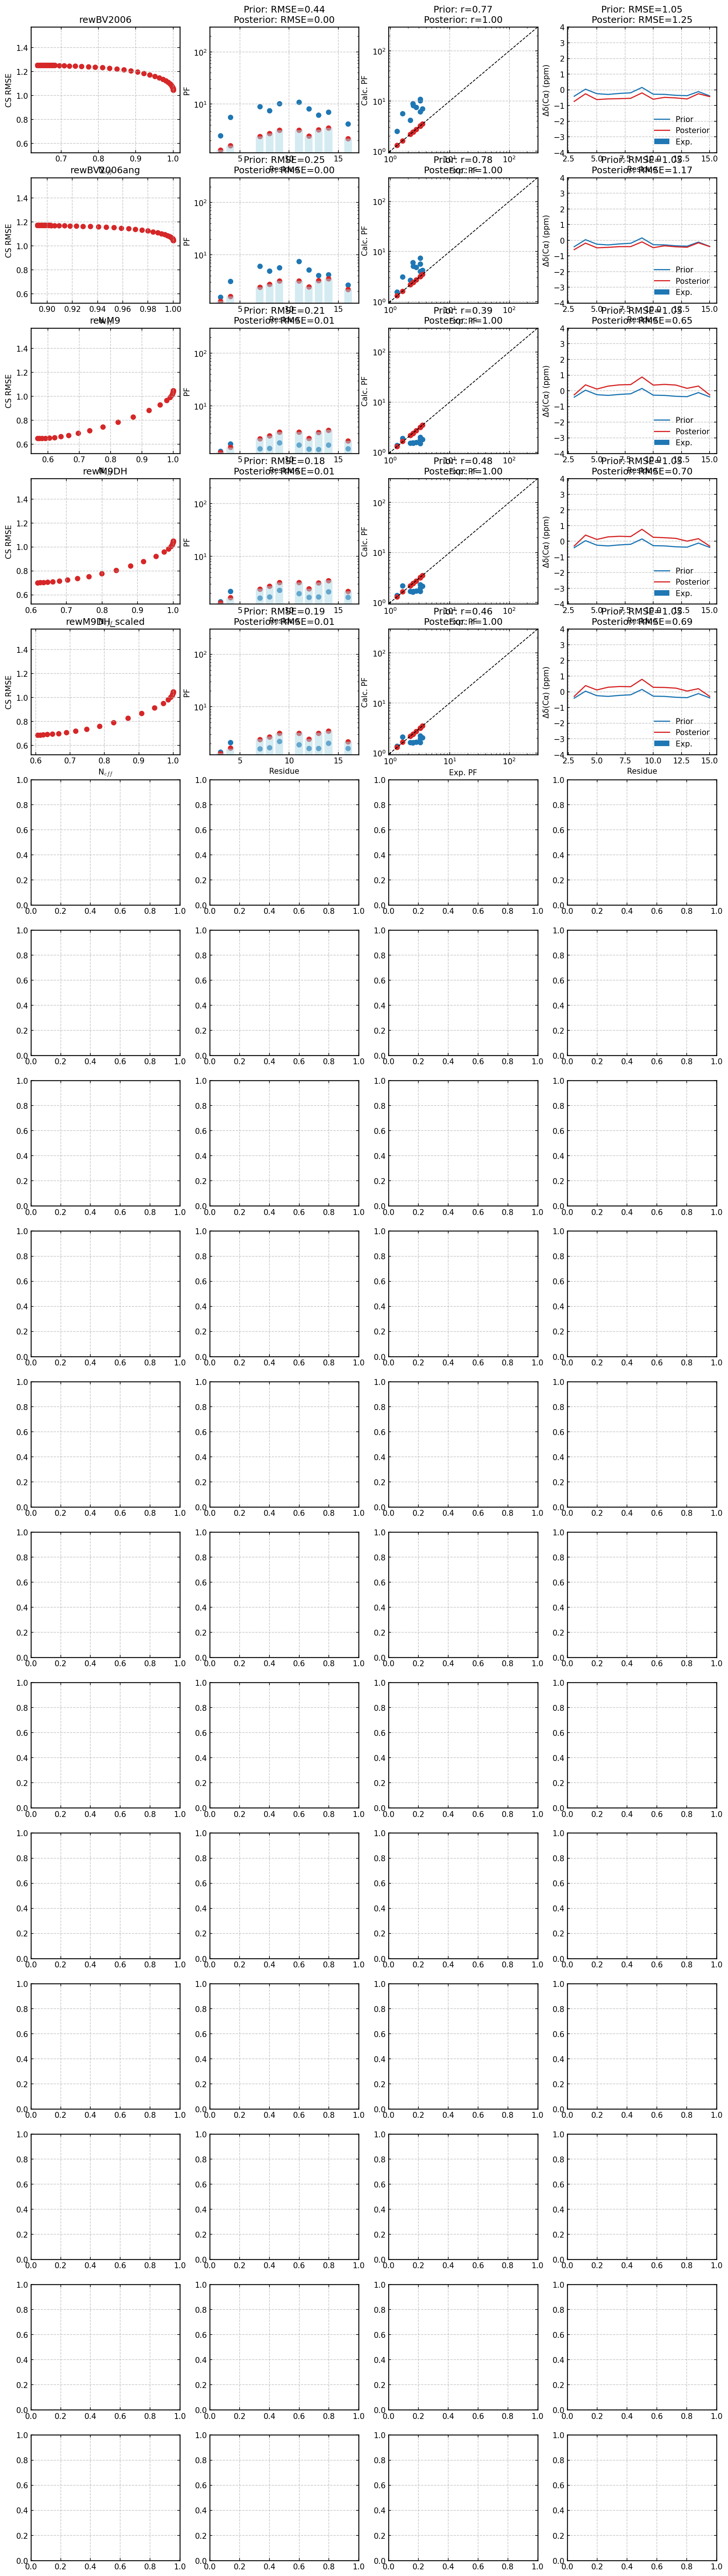

In [2]:
proteins = ['AAQAA3', 'ACTR', 'aSyn', 'BecN', 'ChiZ', 'd131d', 'drkN', 'NTail']
models = ['rewBV2006', 'rewBV2006ang', 'rewM9', 'rewM9DH', 'rewM9DH_scaled',
          'rewM10', 'rewM10DH','rewM10DH_scaled','rewM11', 'rewM11DH', 'rewM11DH_scaled',
          'rewM12', 'rewM12DH','rewM12DH_scaled','rewM14', 'rewM14DH', 'rewM14DH_scaled']

for protein in proteins:
    print(protein)
 
    nucleus='CA'
    all_types = ['CA', 'CB', 'HA', 'C', 'H', 'HN', 'N']

    label_dict = {'CA': 'Cα', 'HA': 'Hα', 'CB': 'Cβ', 'C': "C'"}
    axlim_dict = {'CA': 4, 'HA': 1, 'CB': 4, 'C': 4}

    traj_names = np.sort(find_xtc_filenames(f'../../MD_DATA/{protein}/'))

    n_models = len(models)
    ncols=4
    fig, axes = plt.subplots(nrows=n_models, ncols=ncols, figsize=(ncols*4., 3.5 * n_models))

    # load CS data
    for i in range(len(traj_names)):
        if i==0:
            gen_df = load_generated_shifts(f'../../MD_DATA/{protein}/CS/CS_{traj_names[i][:-4]}.csv')
        else:
            tmp_df = load_generated_shifts(f'../../MD_DATA/{protein}/CS/CS_{traj_names[i][:-4]}.csv')
            gen_df= pd.concat([gen_df, tmp_df], axis=1, join = 'outer', ignore_index=True)

    # experimental CS data
    exp_dict = load_and_filter_experimental_shifts(f'../../ORTHOGONAL_EXP_DATA/{protein}/CS.dat', '../../code/cs_stat_aa_filt.csv', ATOM_TYPES=all_types)

    # get standardised deltas
    std_delta_cs, keys = standardize_deltas(gen_df, exp_dict, predictor = 'Sparta+')

    # load RC shifts
    potenci = load_potenci_shifts(f'../../ORTHOGONAL_EXP_DATA/potenci_shifts/{protein}_RCshifts.dat', ATOM_TYPES=all_types)

    # calculate experimental secondary shifts
    potenci_residues = []
    potenci_shifts = []
    for key in list(potenci.keys()):
        if key[1]==nucleus:
            potenci_residues.append(key[0])
            potenci_shifts.append(potenci[key])

    exp_residues = []
    exp_shifts = []
    for key in list(exp_dict.keys()):
        if key[1]==nucleus:
            exp_residues.append(key[0])
            exp_shifts.append(exp_dict[key])

    potenci_residues = np.array(potenci_residues)
    potenci_shifts = np.array(potenci_shifts)
    exp_residues = np.array(exp_residues)
    exp_shifts = np.array(exp_shifts)

    common_residues = np.intersect1d(potenci_residues, exp_residues)
    indices_p = np.where(np.isin(potenci_residues, common_residues))[0]
    indices_e = np.where(np.isin(exp_residues, common_residues))[0]
    SSexp = exp_shifts[indices_e] - potenci_shifts[indices_p]

    for i, model in enumerate(models):
        exp, residues, priorPF, rewPF, chi2, phi, thetas, stats, idxs = load_pf_data(protein, model_name=model)
        if model in ('rewBV2006', 'rewBV2006ang'):
            wopt_array = np.load(f"../../MD_DATA/{protein}/{model}/wopt_array.npy")
            wopt = np.load(f"../../MD_DATA/{protein}/{model}/wopt.npy")
        else:
            wopt_array = np.load(f"../../MD_DATA/{protein}/{model}/log_lambda_wopt_array.npy")
            wopt = np.load(f"../../MD_DATA/{protein}/{model}/log_lambda_wopt.npy")

        savedf = pd.DataFrame()
        savedf['Neff'] = phi

        expPF = np.array(exp["PF"][idxs])
        rmse_prior = RMSE(np.log10(expPF), np.log10(priorPF))
        rmse_post = RMSE(np.log10(expPF), np.log10(rewPF))
        r_prior = scipy.stats.pearsonr(np.log10(expPF), np.log10(priorPF))[0]
        r_post = scipy.stats.pearsonr(np.log10(expPF), np.log10(rewPF))[0]

        # calculate RMSE to validation data
        validation_rmse = []
        for W in wopt_array:
            rmse = get_RMSE(std_delta_cs, weights=W)
            validation_rmse.append(rmse)
        cs_prior_rmse = get_RMSE(std_delta_cs, weights=np.ones(std_delta_cs.shape[1])/ std_delta_cs.shape[1])

        savedf['CS_RMSE'] = validation_rmse

        # --- Plot 1: neff vs RMSE with validation data ---
        ax = axes[i, 0]
        ax.scatter(phi, validation_rmse, c="tab:red")
        ax.set_xlabel("N$_{eff}$"); ax.set_ylabel("CS RMSE")
        ax.set_title(f"{model}")
        ax.set_ylim(0.5 * validation_rmse[0], 1.5 * validation_rmse[0])

        # --- Plot 2: Per-residue PFs ---
        ax = axes[i, 1]
        ax.set_title(f"Prior: RMSE={rmse_prior:.2f}\nPosterior: RMSE={rmse_post:.2f}")
        ax.bar(residues, expPF, color="lightblue", alpha=0.5, label="Exp.")
        ax.scatter(residues, priorPF, color="tab:blue", label="Prior")
        ax.scatter(residues, rewPF, color="tab:red",label="Posterior")
        ax.set_yscale("log")
        ax.set_ylim(0,300)
        ax.set_xlabel("Residue"); ax.set_ylabel("PF")

        # --- Plot 3: PF exp vs calc prior and posterior ---
        ax = axes[i, 2]
        ax.set_title(f"Prior: r={r_prior:.2f}\nPosterior: r={r_post:.2f}")
        ax.scatter(expPF, priorPF, color="tab:blue", label="Prior")
        ax.scatter(expPF, rewPF, color="tab:red", label="Posterior")
        ax.plot([-10, 1e3], [-10, 1e3], color='black', linestyle='dashed', linewidth=1)
        ax.set_yscale("log")
        ax.set_xscale("log")
        ax.set_ylim(0,300)
        ax.set_xlim(0,300)
        ax.set_xlabel("Exp. PF"); ax.set_ylabel("Calc. PF")

        # --- Plot 4: secondary CA shifts exp vs calculated prior and posterior ---

        
        ax = axes[i, 3]

        # prior and posterior RMSE
        ax.set_title(f"Prior: RMSE={cs_prior_rmse:.2f}\nPosterior: RMSE={validation_rmse[-1]:.2f}")

        # experimental values
        ax.bar(exp_residues[indices_e], SSexp, color = 'lightblue', alpha=0.5, label='Exp.')
        ax.set_ylim(-axlim_dict[nucleus],axlim_dict[nucleus])
        ax.set_xlabel("Residue"); ax.set_ylabel(f"Δδ({label_dict[nucleus]}) (ppm)")

        # calculated secondary shifts from models (before/after reweighting)
        calc_vals = []
        calc_residues = []
        for res in potenci_residues:
            try:
                calc_vals.append(list(gen_df.loc[res, nucleus]))
                calc_residues.append(res)
            except KeyError:
                continue

        calc_residues = np.array(calc_residues)
        calc_vals = np.array(calc_vals).T

        # Average across models
        prior = np.average(calc_vals, axis=0)  
        posterior = np.average(calc_vals, weights=wopt, axis=0)

        # Align Potenci shifts with calc_residues
        indices_p2 = np.where(np.isin(potenci_residues, calc_residues))[0]
        potenci_for_calc = potenci_shifts[indices_p2]

        # Now compute secondary shifts
        SSprior = prior - potenci_for_calc
        SSposterior = posterior - potenci_for_calc

        ax.plot(calc_residues, SSprior, color="tab:blue", label="Prior", linewidth=1.5)
        ax.plot(calc_residues, SSposterior, color="tab:red", label="Posterior", linewidth=1.5)

        # set legend
        ax.legend(loc='lower right')

        # save validation diff data 
        savedf.to_csv(outpath+f"{protein}_{model}_CS_validation.csv")

        
    plt.tight_layout(rect=[0, 0, 1, 0.97])
    plt.savefig(outpath+f"{protein}_HDXrew_CS_all.png", dpi=200, bbox_inches="tight")
    plt.close()
        


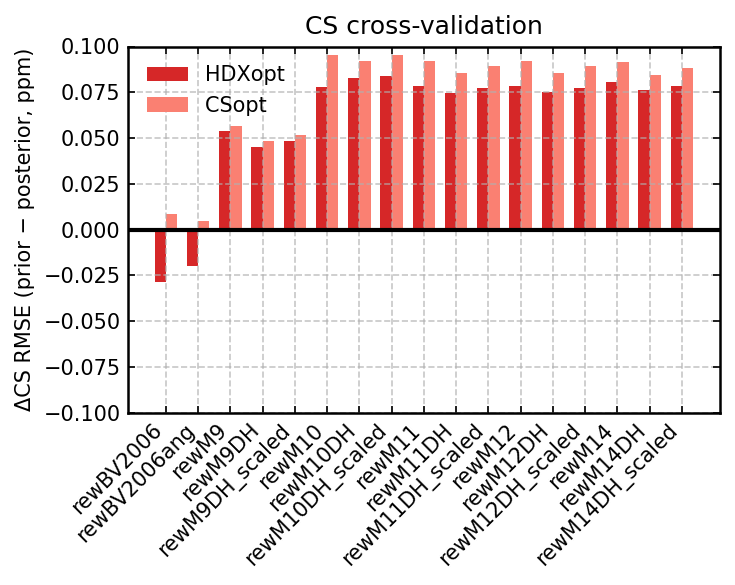

In [3]:
proteins = ['AAQAA3', 'ACTR', 'aSyn', 'BecN', 'ChiZ', 'd131d', 'drkN', 'NTail']
models = ['rewBV2006', 'rewBV2006ang', 'rewM9', 'rewM9DH', 'rewM9DH_scaled',
          'rewM10', 'rewM10DH','rewM10DH_scaled','rewM11', 'rewM11DH', 'rewM11DH_scaled',
          'rewM12', 'rewM12DH','rewM12DH_scaled','rewM14', 'rewM14DH', 'rewM14DH_scaled']

# summary barplot (delta CS RMSE prior vs posterior)
# posterior 1 (HDXopt): best HDX fit (final point of the reweighting curve)
# posterior 2 (RDCopt): best validation data fit (minimum point of the reweighting curve - if no improvement this is simply the prior)

mean_diff1 = []
mean_diff2 = []

for model in models:

    prior = []
    post1 = []
    post2 = []

    for protein in proteins:
        dat = pd.read_csv(outpath+f'{protein}_{model}_CS_validation.csv')

        prior.append(list(dat['CS_RMSE'])[0])
        post1.append(list(dat['CS_RMSE'])[-1])
        post2.append(np.min(dat['CS_RMSE']))

    diff1 = np.array(prior)- np.array(post1)
    diff2 = np.array(prior)- np.array(post2)

    mean_diff1.append(np.mean(diff1))
    mean_diff2.append(np.mean(diff2))

df = pd.DataFrame()
df['Model']=models
df['HDXopt'] = mean_diff1
df['CSopt'] = mean_diff2





x = np.arange(len(df['Model']))          # positions for models
width = 0.35                             # width of the bars

fig, ax = plt.subplots(figsize=(5,4))

ax.bar(x - width/2, df['HDXopt'], width, label='HDXopt', color = 'tab:red')
ax.bar(x + width/2, df['CSopt'], width, label='CSopt ', color = 'salmon')

ax.set_ylabel('ΔCS RMSE (prior − posterior, ppm)')
ax.set_title('CS cross-validation')
ax.set_xticks(x)
ax.axhline(0, color='black')
ax.set_ylim(-0.1,0.1)
ax.set_xticklabels(df['Model'], rotation=45, ha='right')
ax.legend(loc='upper left')

plt.tight_layout()
plt.savefig(outpath+f'CS_validation_summary.png',dpi=300)






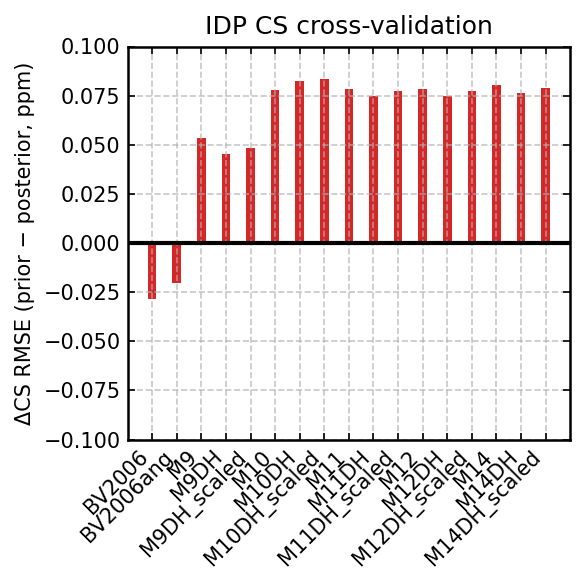

In [4]:
proteins = ['AAQAA3', 'ACTR', 'aSyn', 'BecN', 'ChiZ', 'd131d', 'drkN', 'NTail']
models = ['rewBV2006', 'rewBV2006ang', 'rewM9', 'rewM9DH', 'rewM9DH_scaled',
          'rewM10', 'rewM10DH','rewM10DH_scaled','rewM11', 'rewM11DH', 'rewM11DH_scaled',
          'rewM12', 'rewM12DH','rewM12DH_scaled','rewM14', 'rewM14DH', 'rewM14DH_scaled']

labels = [model[3:] for model in models]

# summary barplot (delta CS RMSE prior vs posterior)
# posterior 1 (HDXopt): best HDX fit (final point of the reweighting curve)

mean_diff1 = []
mean_diff2 = []

for model in models:

    prior = []
    post1 = []
    post2 = []

    for protein in proteins:
        dat = pd.read_csv(outpath+f'{protein}_{model}_CS_validation.csv')

        prior.append(list(dat['CS_RMSE'])[0])
        post1.append(list(dat['CS_RMSE'])[-1])
        post2.append(np.min(dat['CS_RMSE']))

    diff1 = np.array(prior)- np.array(post1)
    diff2 = np.array(prior)- np.array(post2)

    mean_diff1.append(np.mean(diff1))
    mean_diff2.append(np.mean(diff2))

df = pd.DataFrame()
df['Model']=labels
df['HDXopt'] = mean_diff1
df['CSopt'] = mean_diff2





x = np.arange(len(df['Model']))          # positions for models
width = 0.35                             # width of the bars

fig, ax = plt.subplots(figsize=(4,4))

ax.bar(x, df['HDXopt'], width, label='HDXopt', color = 'tab:red')

ax.set_ylabel('ΔCS RMSE (prior − posterior, ppm)')
ax.set_title('IDP CS cross-validation')
ax.set_xticks(x)
ax.axhline(0, color='black')
ax.set_ylim(-0.1,0.1)
ax.set_xticklabels(df['Model'], rotation=45, ha='right')

plt.tight_layout()
plt.savefig(outpath+f'CS_validation_summary_HDXopt_only.png',dpi=300)






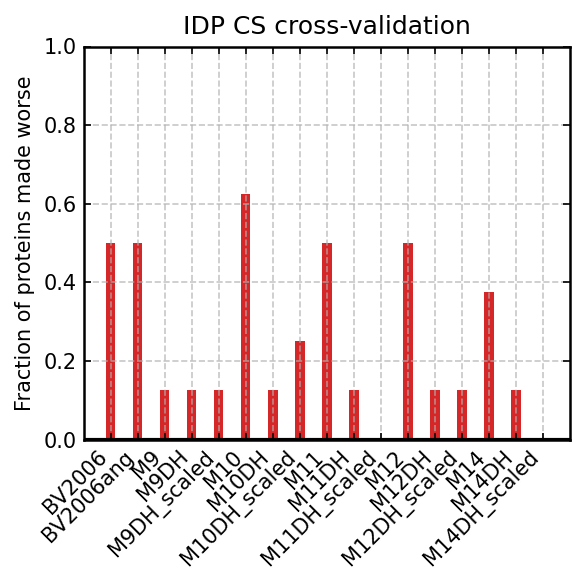

In [5]:
proteins = ['AAQAA3', 'ACTR', 'aSyn', 'BecN', 'ChiZ', 'd131d', 'drkN', 'NTail']
models = ['rewBV2006', 'rewBV2006ang', 'rewM9', 'rewM9DH', 'rewM9DH_scaled',
          'rewM10', 'rewM10DH','rewM10DH_scaled','rewM11', 'rewM11DH', 'rewM11DH_scaled',
          'rewM12', 'rewM12DH','rewM12DH_scaled','rewM14', 'rewM14DH', 'rewM14DH_scaled']

labels = [model[3:] for model in models]

# summary barplot (delta CS RMSE prior vs posterior)
# posterior 1 (HDXopt): number of proteins that got worse by more than 0.01 ppm

mean_diff1 = []
mean_diff2 = []

for model in models:

    prior = []
    post1 = []

    for protein in proteins:
        if not os.path.exists(outpath+f'{protein}_{model}_CS_validation.csv'):
            print(f'No cross-validation/reweighting anlaysis exists for {protein}/{model}, skipping ...')
            continue
        dat = pd.read_csv(outpath+f'{protein}_{model}_CS_validation.csv')

        prior.append(list(dat['CS_RMSE'])[0])
        post1.append(list(dat['CS_RMSE'])[-1])

    diff1 = np.array(prior)- np.array(post1)

    worse = (diff1 < -0.01)*1

    mean_diff1.append(np.mean(worse))

df = pd.DataFrame()
df['Model']=models
df['HDXopt'] = mean_diff1





x = np.arange(len(df['Model']))          # positions for models
width = 0.35                             # width of the bars

fig, ax = plt.subplots(figsize=(4,4))

ax.bar(x, df['HDXopt'], width, label='HDXopt', color = 'tab:red')

ax.set_ylabel('Fraction of proteins made worse')
ax.set_title('IDP CS cross-validation')
ax.set_xticks(x)
ax.axhline(0, color='black')
ax.set_ylim(0,1)
ax.set_xticklabels(labels, rotation=45, ha='right')

plt.tight_layout()
plt.savefig(outpath+f'CS_validation_summary_HDXopt_only_fraction_made_worse.png',dpi=300)






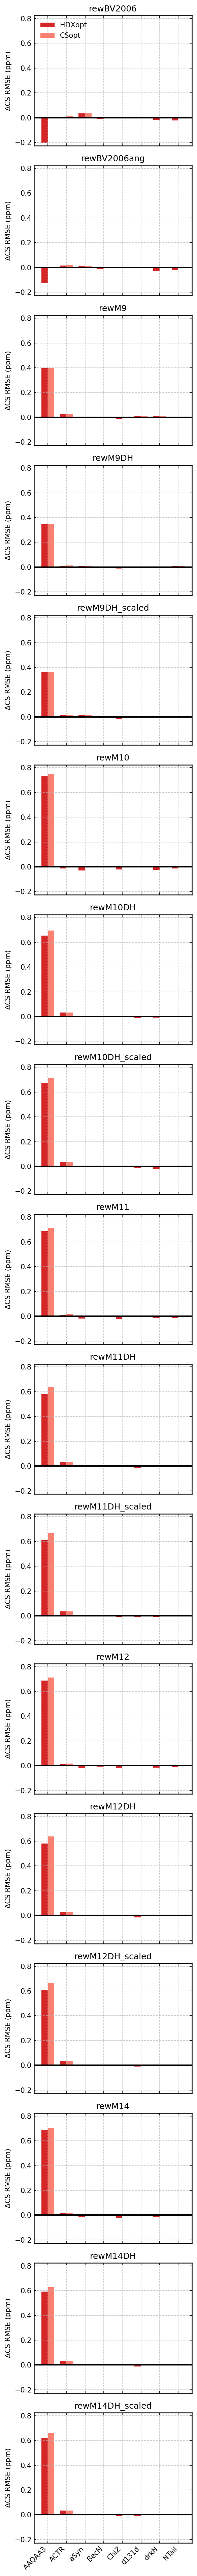

In [6]:


# ---- Compute ΔRMSE FOR EACH PROTEIN × MODEL ----
rows = []

for model in models:
    for protein in proteins:

        dat = pd.read_csv(outpath + f'{protein}_{model}_CS_validation.csv')

        prior = list(dat['CS_RMSE'])[0]
        post1 = list(dat['CS_RMSE'])[-1]
        post2 = np.min(dat['CS_RMSE'])

        delta_HDXopt = prior - post1
        delta_CSopt = prior - post2

        rows.append({
            "Model": model,
            "Protein": protein,
            "HDXopt": delta_HDXopt,
            "CSopt": delta_CSopt
        })

df = pd.DataFrame(rows)


# ---- PLOTTING ----
n_models = len(models)
x = np.arange(len(proteins))
width = 0.35

fig, axes = plt.subplots(
    n_models, 1,
    figsize=(4, 3 * n_models),
    sharex=True, sharey=True
)

if n_models == 1:
    axes = [axes]  # make iterable if only one model

# global y-limits
ymin = df[["HDXopt", "CSopt"]].min().min() * 1.1
ymax = df[["HDXopt", "CSopt"]].max().max() * 1.1

for idx, model in enumerate(models):
    ax = axes[idx]
    sub = df[df["Model"] == model]

    ax.bar(x - width/2, sub["HDXopt"], width, label="HDXopt", color="tab:red")
    ax.bar(x + width/2, sub["CSopt"], width, label="CSopt", color="salmon")

    ax.axhline(0, color="black")
    ax.set_ylim(ymin, ymax)
    ax.set_title(model)
    ax.set_ylabel("ΔCS RMSE (ppm)")

    if idx == 0:
        ax.legend(loc="upper left")

axes[-1].set_xticks(x)
axes[-1].set_xticklabels(proteins, rotation=45, ha='right')

plt.tight_layout()
plt.savefig(outpath + "CS_validation_per_protein_per_model.png", dpi=300)

